In [1]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist
from sklearn.cluster import KMeans
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    classification_report
)

HO_TEN = "TRẦN THỊ MỸ DUNG"
MSSV = "6451071008"

def thong_tin(cau):
    print(f"Họ tên: {HO_TEN}")
    print(f"MSSV: {MSSV}")
    print(f"BÀI 5 - {cau}")
    print("-" * 50)

# Đọc bộ dữ liệu MNIST từ Keras
thong_tin("Doc du lieu")

(_, _), (images, labels) = mnist.load_data()

print("Kích thước ảnh:", images.shape)
print("Kích thước nhãn:", labels.shape)
print("Các lớp:", np.unique(labels))


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - Doc du lieu
--------------------------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước ảnh: (10000, 28, 28)
Kích thước nhãn: (10000,)
Các lớp: [0 1 2 3 4 5 6 7 8 9]


In [2]:

# Chuẩn hóa và chuyển ảnh 28x28 thành vector 784 chiều
thong_tin("Chuan hoa du lieu")

X = images.astype("float32") / 255.0
X = X.reshape(X.shape[0], -1)

y = labels.copy()

print("Kích thước sau khi làm phẳng:", X.shape)
print("Giá trị nhỏ nhất:", X.min())
print("Giá trị lớn nhất:", X.max())


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - Chuan hoa du lieu
--------------------------------------------------
Kích thước sau khi làm phẳng: (10000, 784)
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 1.0


In [3]:

# Gom dữ liệu MNIST thành 10 cụm bằng thuật toán K-Means
thong_tin("Gom cum K-Means")

kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X)

print("Số cụm:", kmeans.n_clusters)
print("Kích thước nhãn cụm:", cluster_labels.shape)

print("\nSố ảnh trong mỗi cụm:")
for i in range(10):
    print(f"Cụm {i}: {np.sum(cluster_labels == i)} ảnh")

print("\nInertia:", kmeans.inertia_)


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - Gom cum K-Means
--------------------------------------------------
Số cụm: 10
Kích thước nhãn cụm: (10000,)

Số ảnh trong mỗi cụm:
Cụm 0: 1190 ảnh
Cụm 1: 736 ảnh
Cụm 2: 1082 ảnh
Cụm 3: 884 ảnh
Cụm 4: 878 ảnh
Cụm 5: 1287 ảnh
Cụm 6: 792 ảnh
Cụm 7: 998 ảnh
Cụm 8: 1192 ảnh
Cụm 9: 961 ảnh

Inertia: 389395.25


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - Hien thi tam cum
--------------------------------------------------


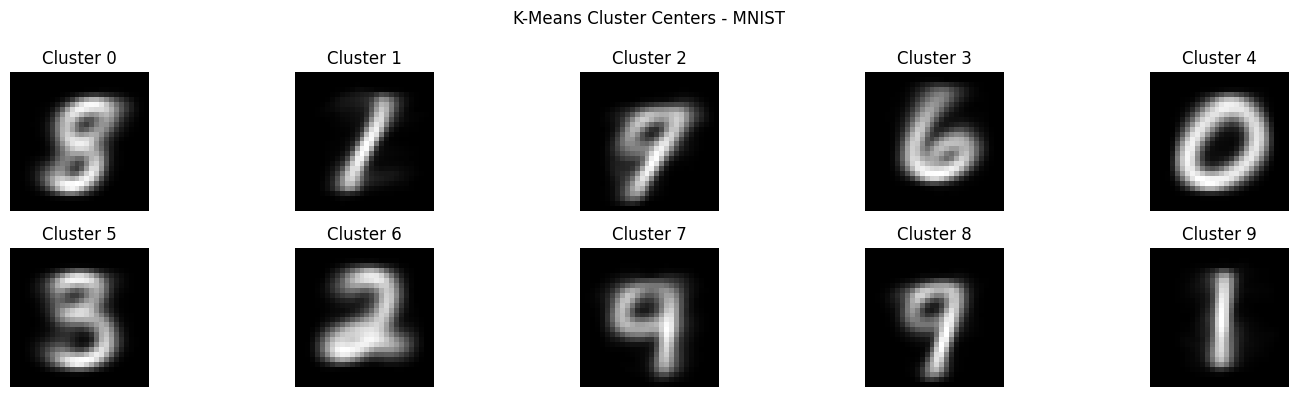

In [4]:

# Hiển thị tâm của 10 cụm dưới dạng ảnh chữ số
thong_tin("Hien thi tam cum")

centers = kmeans.cluster_centers_.reshape(10, 28, 28)

plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(centers[i], cmap="gray")
    plt.title(f"Cluster {i}")
    plt.axis("off")

plt.suptitle("K-Means Cluster Centers - MNIST")
plt.tight_layout()
plt.show()


In [5]:

# So sánh kết quả gom cụm với nhãn chữ số thực tế
thong_tin("So sanh nhan")

cluster_to_label = {}

for i in range(10):
    true_labels = y[cluster_labels == i]
    cluster_to_label[i] = np.bincount(
        true_labels, minlength=10
    ).argmax()

y_pred = np.array([
    cluster_to_label[c] for c in cluster_labels
])

print("Nhãn đại diện cho từng cụm:")
for cluster, label in cluster_to_label.items():
    print(f"Cụm {cluster} -> Chữ số {label}")

print("\nAccuracy sau khi gán nhãn:",
      accuracy_score(y, y_pred))

print("Adjusted Rand Index:",
      adjusted_rand_score(y, cluster_labels))

print("Normalized Mutual Information:",
      normalized_mutual_info_score(y, cluster_labels))

print("\nClassification Report:")
print(classification_report(
    y, y_pred,
    labels=range(10),
    zero_division=0
))


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - So sanh nhan
--------------------------------------------------
Nhãn đại diện cho từng cụm:
Cụm 0 -> Chữ số 8
Cụm 1 -> Chữ số 1
Cụm 2 -> Chữ số 7
Cụm 3 -> Chữ số 6
Cụm 4 -> Chữ số 0
Cụm 5 -> Chữ số 3
Cụm 6 -> Chữ số 2
Cụm 7 -> Chữ số 4
Cụm 8 -> Chữ số 7
Cụm 9 -> Chữ số 1

Accuracy sau khi gán nhãn: 0.5887
Adjusted Rand Index: 0.3790787886591178
Normalized Mutual Information: 0.5016601071638936

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88       980
           1       0.67      0.99      0.80      1135
           2       0.87      0.67      0.76      1032
           3       0.53      0.67      0.59      1010
           4       0.42      0.43      0.43       982
           5       0.00      0.00      0.00       892
           6       0.89      0.83      0.86       958
           7       0.36      0.79      0.49      1028
           8       0.46      0.56      0.5

Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - Confusion Matrix
--------------------------------------------------


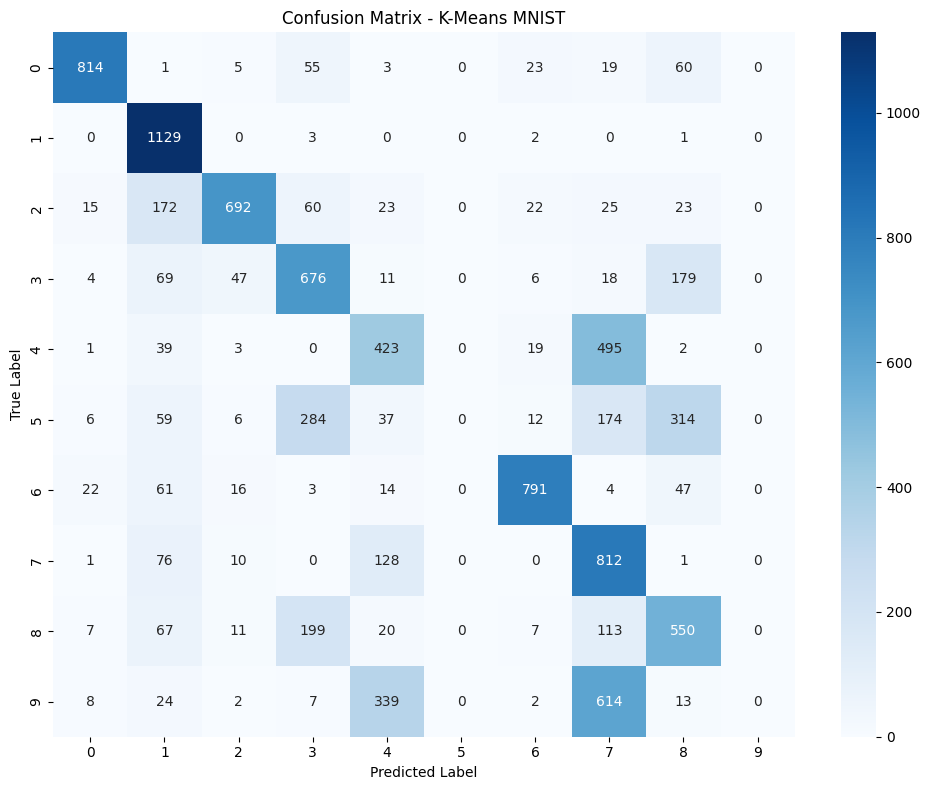

In [6]:

# Vẽ ma trận nhầm lẫn giữa nhãn dự đoán và nhãn thực tế
thong_tin("Confusion Matrix")

cm = confusion_matrix(y, y_pred, labels=range(10))

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix - K-Means MNIST")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 5 - Ket qua gom cum
--------------------------------------------------


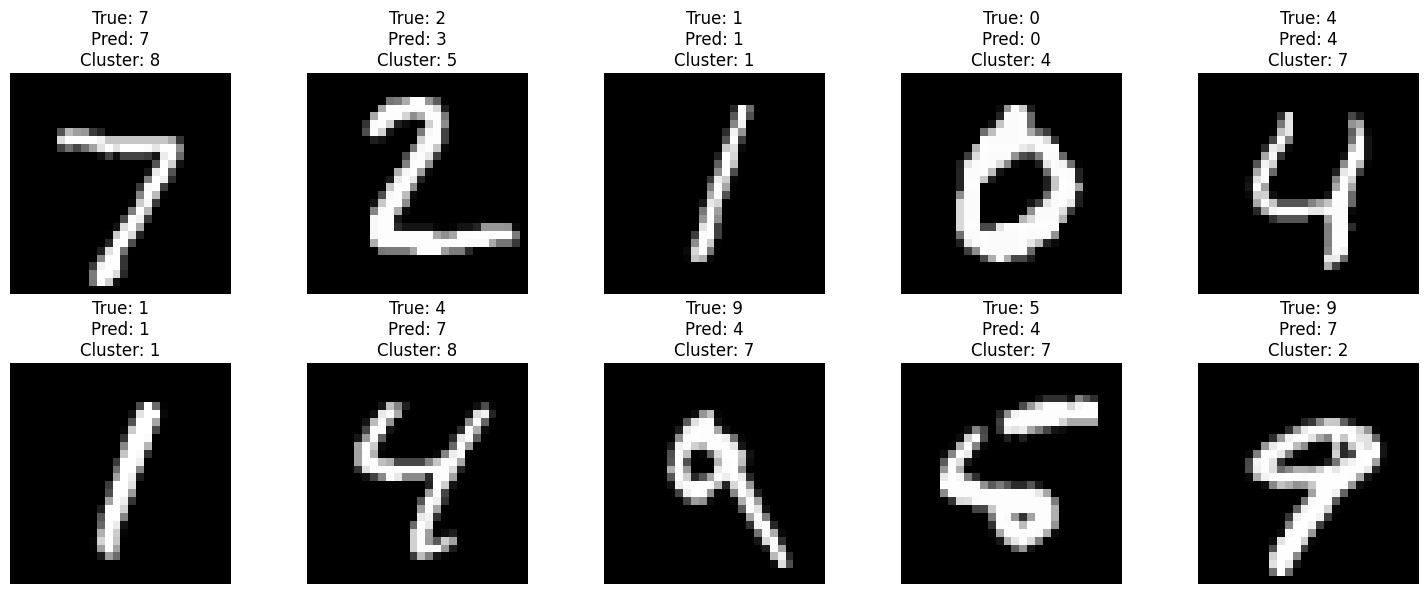

In [7]:

# Hiển thị 10 ảnh cùng nhãn thật và kết quả gom cụm
thong_tin("Ket qua gom cum")

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(
        f"True: {y[i]}\n"
        f"Pred: {y_pred[i]}\n"
        f"Cluster: {cluster_labels[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
